## Dependencies

In [1]:
%matplotlib inline

In [2]:
import pandas as pd

In [3]:
import sys
sys.path.append('../')

%load_ext autoreload
%autoreload 2

from libs import ios
from libs import vis
from libs import setup

Total combinations of features: 1023


## Setup

In [4]:
VERSION = 3

VAR_X = ['mean', 'median', 'mode']
DIR = f'../../results/v{VERSION}/gender/predictions/comparison/rs*/classification/_<VAR_X>/cut_*/*'
METRIC = 'test_auc'
ASCENDING = False

In [5]:
vis.sns_paper_style()

## Data

In [6]:
df_results_mean = ios.load_json_files_to_dataframe(DIR.replace('<VAR_X>', 'mean'), include_fn=True)
df_results_median = ios.load_json_files_to_dataframe(DIR.replace('<VAR_X>', 'median'), include_fn=True)
df_results_mode = ios.load_json_files_to_dataframe(DIR.replace('<VAR_X>', 'mode'), include_fn=True)
df_results = pd.concat([df_results_mean, df_results_median, df_results_mode], ignore_index=True)

# A few mods:
df_results.loc[:,'rs'] = df_results.fn.apply(lambda v: int(v.split('/rs')[-1].split('/')[0]))
df_results = df_results.query("rs != 12345").copy()
df_results.shape

df_results.shape

(12770, 31)

In [7]:
df_results.columns

Index(['strategy_id', 'features_id', 'y', 'features', 'nfeatures',
       'cat_features', 'best_params', 'best_score', 'best_iteration',
       'test_size', 'random_state', 'loss_function', 'eval_metric',
       'train_eval', 'test_accuracy', 'test_f1', 'test_precision',
       'test_recall', 'test_auc', 'all_accuracy', 'all_f1', 'all_precision',
       'all_recall', 'all_auc', 'f_name', 'labels', 'y_test', 'y_pred',
       'y_pred_proba', 'fn', 'rs'],
      dtype='object')

In [8]:
cols = ['y','features_id', 'strategy_id', 'features', 'nfeatures', 'train_eval','test_accuracy','all_accuracy','test_f1','test_precision','test_recall','test_auc','all_auc','f_name','rs']
df_results[cols].sort_values(METRIC, ascending=ASCENDING)

,y,features_id,strategy_id,features,nfeatures,train_eval,test_accuracy,all_accuracy,test_f1,test_precision,test_recall,test_auc,all_auc,f_name,rs
191,gender_mean,607,1,"[gender_n, gender_nw, mean_ngender_rn, mean_ng...",5,0.223454,0.875000,0.849398,0.882540,0.900000,0.872086,0.970959,0.958966,mean_607_1,2
461,gender_mean,838,1,"[gender_n, gender_nw, mean_ngender_rn, mean_ng...",6,0.091783,0.875000,0.873494,0.874603,0.921569,0.856061,0.970865,0.964734,mean_838_1,2
513,gender_mean,835,1,"[gender_n, gender_nw, single_char, mean_ngende...",6,0.180950,0.843750,0.855422,0.847291,0.883333,0.830420,0.970772,0.959608,mean_835_1,2
155,gender_mean,950,1,"[ngender_n, gender_n, gender_nw, mean_ngender_...",7,0.218638,0.875000,0.867470,0.874603,0.921569,0.856061,0.970678,0.964145,mean_950_1,2
994,gender_mean,376,1,"[gender_nw, mean_ngender_rn, mean_ngender_rw, ...",4,0.313230,0.812500,0.813253,0.819902,0.846154,0.809441,0.969703,0.951487,mean_376_1,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10169,gender_median,5,4,[single_char],1,1.055826,0.424242,0.439759,0.338095,0.297101,0.416667,0.591293,0.598405,median_5_4,3
9893,gender_median,28,4,"[gender_n, gender_nw]",2,0.576970,0.545455,0.542169,0.427350,0.362963,0.520202,0.587421,0.634576,median_28_4,3
12128,gender_mode,4,5,[gender_nw],1,0.779647,0.454545,0.572289,0.339506,0.303704,0.384921,0.569396,0.654956,mode_4_5,2
12351,gender_mode,28,5,"[gender_n, gender_nw]",2,0.693255,0.424242,0.536145,0.325889,0.307018,0.365079,0.545129,0.622055,mode_28_5,2


In [9]:
best_id = df_results[METRIC].idxmax()
best_id

191

In [10]:
df_results.loc[[best_id], ['y', 'features', 'nfeatures',  'train_eval','test_f1','test_auc', 'rs']]

,y,features,nfeatures,train_eval,test_f1,test_auc,rs
191,gender_mean,"[gender_n, gender_nw, mean_ngender_rn, mean_ng...",5,0.223454,0.88254,0.970959,2


In [11]:
df_results.loc[best_id].features

['gender_n',
 'gender_nw',
 'mean_ngender_rn',
 'mean_ngender_rw',
 'mean_ngender_nw']

In [12]:
df_results.loc[best_id].strategy_id, setup.STRATEGY[df_results.loc[best_id].strategy_id]

(1, {'cuts': [0.33, 0.66], 'gt_agg': 'mean'})

In [13]:
df_results.loc[best_id]

strategy_id                                                       1
features_id                                                     607
y                                                       gender_mean
features          [gender_n, gender_nw, mean_ngender_rn, mean_ng...
nfeatures                                                         5
cat_features                                  [gender_n, gender_nw]
best_params       {'depth': 6, 'learning_rate': 0.1, 'l2_leaf_re...
best_score        {'learn': {'MultiClass': 0.22345421342843091},...
best_iteration                                                  199
test_size                                                       0.2
random_state                                                      2
loss_function                                            MultiClass
eval_metric                                              MultiClass
train_eval                                                 0.223454
test_accuracy                                   

In [14]:
metric = df_results.loc[best_id].y.replace('gender_','')
cut_id = df_results.loc[best_id].strategy_id
rs = df_results.loc[best_id].rs

f_name = DIR.replace('rs*',f'rs{rs}').replace('<VAR_X>', metric).replace('cut_*', f"cut_{cut_id}").replace('/*', "")
f_name = f"{f_name}/{metric}_{df_results.loc[best_id].features_id}_{df_results.loc[best_id].strategy_id}"
f_name

'../../results/v3/gender/predictions/comparison/rs2/classification/_mean/cut_1/mean_607_1'

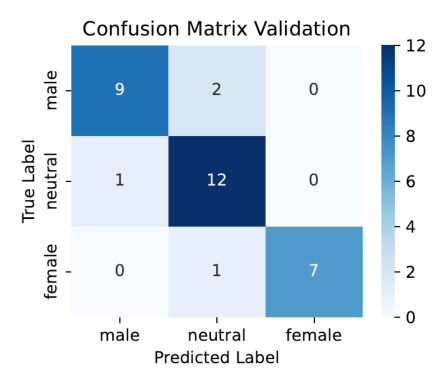

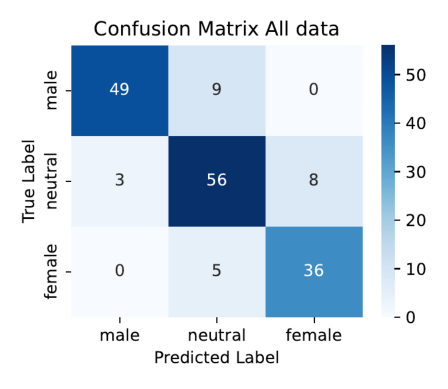

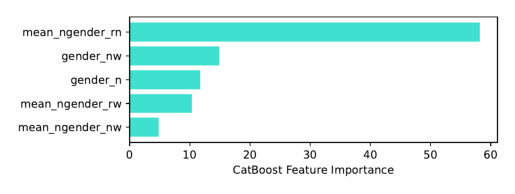

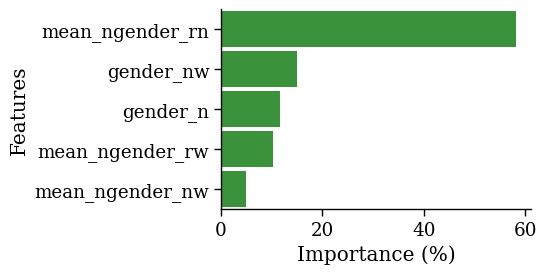

In [15]:
vis.plot_confusion_matrix_from_file(f"{f_name}_confusion_val.pdf")
vis.plot_confusion_matrix_from_file(f"{f_name}_confusion_all.pdf")
vis.plot_importance_from_file(f"{f_name}_feature_importance.pdf")
vis.replot_importance(f_name, regressor=False)

## Per run

In [16]:
df_best_per_run = df_results.loc[df_results.groupby('rs')[METRIC].idxmax(),:].sort_values(METRIC, ascending=ASCENDING)

In [17]:
df_best_per_run[cols+['fn']]

,y,features_id,strategy_id,features,nfeatures,train_eval,test_accuracy,all_accuracy,test_f1,test_precision,test_recall,test_auc,all_auc,f_name,rs,fn
191,gender_mean,607,1,"[gender_n, gender_nw, mean_ngender_rn, mean_ng...",5,0.223454,0.875000,0.849398,0.882540,0.900000,0.872086,0.970959,0.958966,mean_607_1,2,../../results/v3/gender/predictions/comparison...
11190,gender_median,251,4,"[ngender_r, single_char, mean_ngender_rn, mean...",4,0.489966,0.818182,0.813253,0.819311,0.830769,0.822727,0.965516,0.938435,median_251_4,1,../../results/v3/gender/predictions/comparison...
3967,gender_mean,336,3,"[gender_n, gender_nw, mean_ngender_rn, mean_ng...",4,0.224977,0.818182,0.843373,0.815686,0.819483,0.816176,0.942794,0.966004,mean_336_3,3,../../results/v3/gender/predictions/comparison...


In [18]:
# BEST
df_best_per_run[cols]

,y,features_id,strategy_id,features,nfeatures,train_eval,test_accuracy,all_accuracy,test_f1,test_precision,test_recall,test_auc,all_auc,f_name,rs
191,gender_mean,607,1,"[gender_n, gender_nw, mean_ngender_rn, mean_ng...",5,0.223454,0.875000,0.849398,0.882540,0.900000,0.872086,0.970959,0.958966,mean_607_1,2
11190,gender_median,251,4,"[ngender_r, single_char, mean_ngender_rn, mean...",4,0.489966,0.818182,0.813253,0.819311,0.830769,0.822727,0.965516,0.938435,median_251_4,1
3967,gender_mean,336,3,"[gender_n, gender_nw, mean_ngender_rn, mean_ng...",4,0.224977,0.818182,0.843373,0.815686,0.819483,0.816176,0.942794,0.966004,mean_336_3,3


Run id: 1
../../results/v3/gender/predictions/comparison/rs1/classification/_median/cut_4/median_251_4


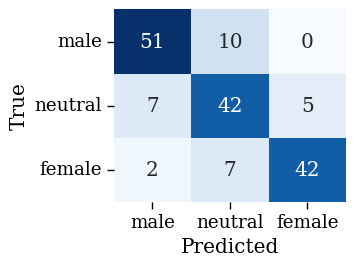

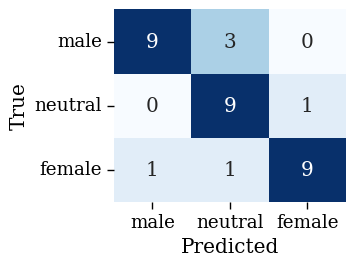

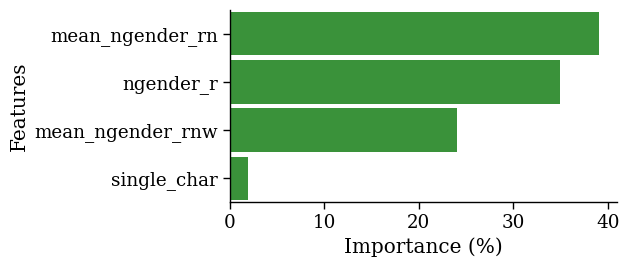

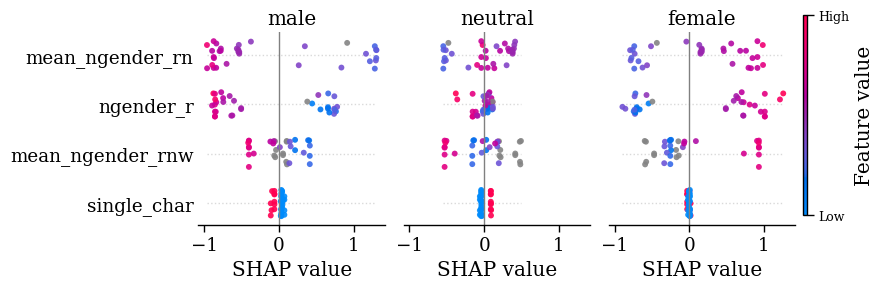

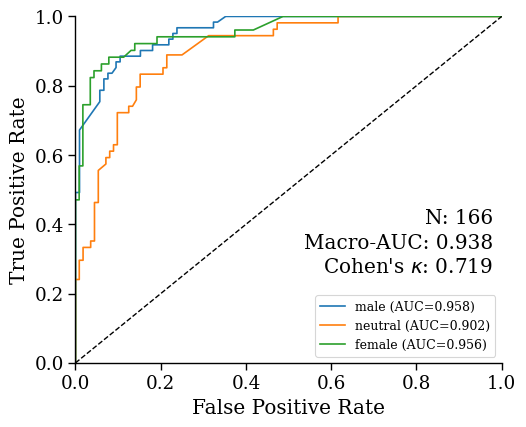

In [19]:
rs = 1
tmp_run = df_best_per_run.query("rs == @rs")
f_name_rs = tmp_run.iloc[0].fn.replace('.json','')
best_overall = best_id == tmp_run.index[0]
print(f"Run id: {rs}" + (" (best overall)" if best_overall else ""))
print(f_name_rs)

fh = 2.5
spw = 3.
vis.replot_confusion_matrix(f_name_rs, test_only=False, figure_width=spw, figure_height=fh, cbar=False)
vis.replot_confusion_matrix(f_name_rs, test_only=True, figure_width=spw, figure_height=fh, cbar=False)
vis.replot_importance(f_name_rs, regressor=False, figure_width=5., figure_height=fh)
vis.replot_shap(f_name_rs, regressor=False, subplot_width=2.6, figure_height=fh)
# vis.replot_rocauc(f_name_rs, test_only=True, figure_width=spw, figure_height=fh)
vis.replot_rocauc(f_name_rs, test_only=False, figure_width=spw, figure_height=fh)

Run id: 2 (best overall)
../../results/v3/gender/predictions/comparison/rs2/classification/_mean/cut_1/mean_607_1


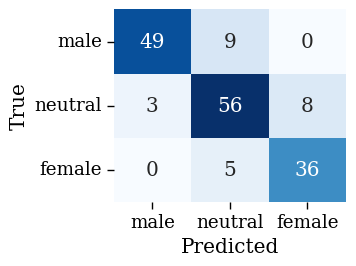

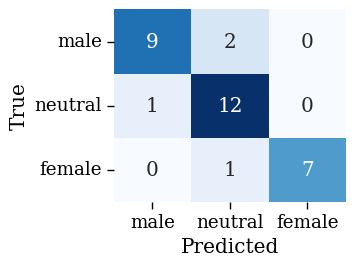

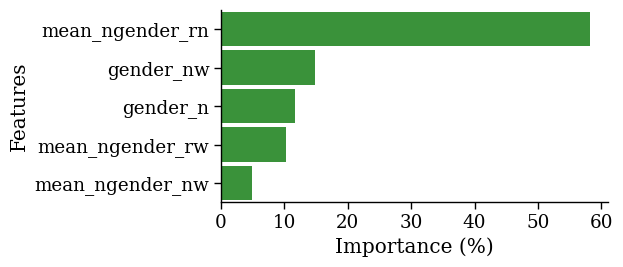

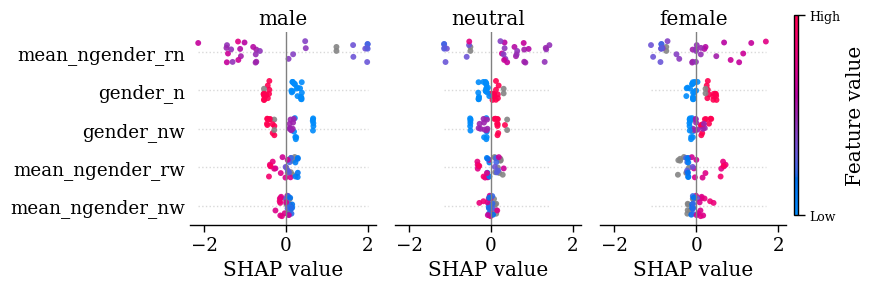

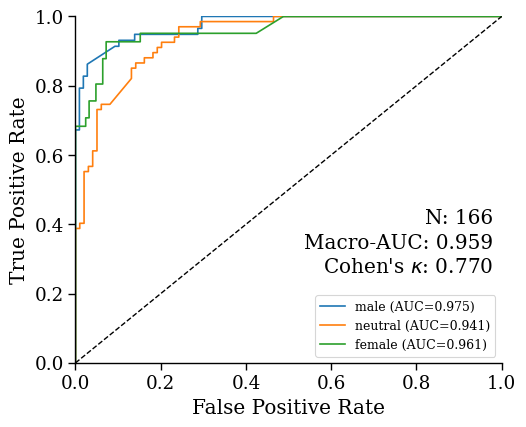

In [20]:
rs = 2
tmp_run = df_best_per_run.query("rs == @rs")
f_name_rs = tmp_run.iloc[0].fn.replace('.json','')
best_overall = best_id == tmp_run.index[0]
print(f"Run id: {rs}" + (" (best overall)" if best_overall else ""))
print(f_name_rs)

fh = 2.5
spw = 3.
vis.replot_confusion_matrix(f_name_rs, test_only=False, figure_width=spw, figure_height=fh, cbar=False)
vis.replot_confusion_matrix(f_name_rs, test_only=True, figure_width=spw, figure_height=fh, cbar=False)
vis.replot_importance(f_name_rs, regressor=False, figure_width=5., figure_height=fh)
vis.replot_shap(f_name_rs, regressor=False, subplot_width=2.6, figure_height=fh)
# vis.replot_rocauc(f_name_rs, test_only=True, figure_width=spw, figure_height=fh)
vis.replot_rocauc(f_name_rs, test_only=False, figure_width=spw, figure_height=fh)

Run id: 3
../../results/v3/gender/predictions/comparison/rs3/classification/_mean/cut_3/mean_336_3


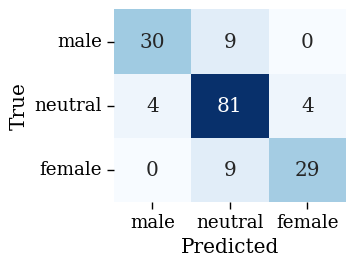

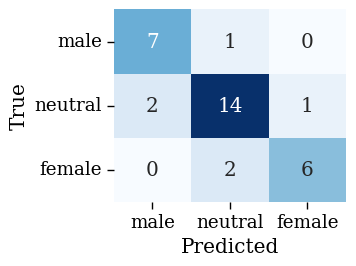

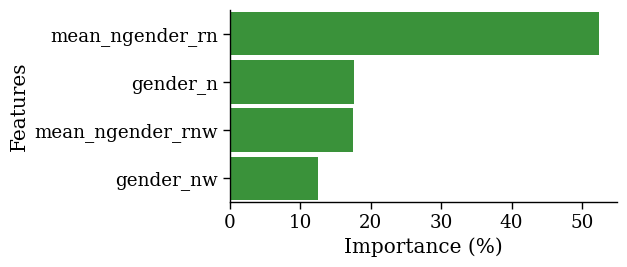

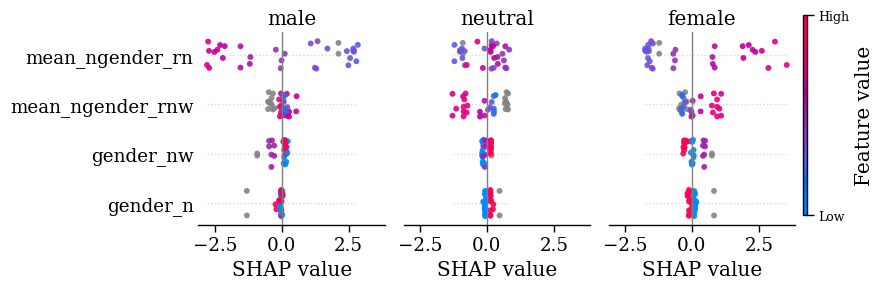

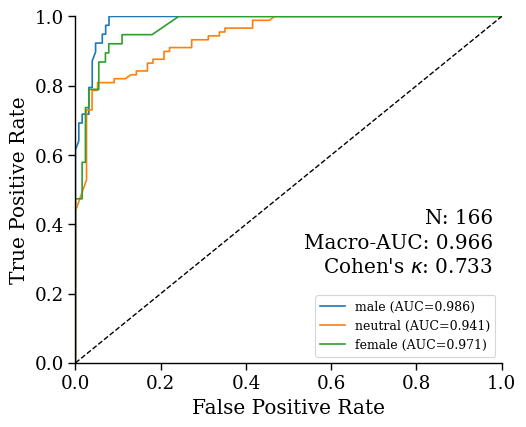

In [21]:
rs = 3
tmp_run = df_best_per_run.query("rs == @rs")
f_name_rs = tmp_run.iloc[0].fn.replace('.json','')
best_overall = best_id == tmp_run.index[0]
print(f"Run id: {rs}" + (" (best overall)" if best_overall else ""))
print(f_name_rs)

fh = 2.5
spw = 3.
vis.replot_confusion_matrix(f_name_rs, test_only=False, figure_width=spw, figure_height=fh, cbar=False)
vis.replot_confusion_matrix(f_name_rs, test_only=True, figure_width=spw, figure_height=fh, cbar=False)
vis.replot_importance(f_name_rs, regressor=False, figure_width=5., figure_height=fh)
vis.replot_shap(f_name_rs, regressor=False, subplot_width=2.6, figure_height=fh)
# vis.replot_rocauc(f_name_rs, test_only=True, figure_width=spw, figure_height=fh)
vis.replot_rocauc(f_name_rs, test_only=False, figure_width=spw, figure_height=fh)